# Telco Customer Churn: EDA, Modelling and Evaluation

**Goal:** predict whether a telecom customer will leave, using account, billing and service data.

This notebook walks through the full analysis. The reusable pieces (loading, cleaning, the
preprocessing + SMOTE pipeline) live in `src/churn/`, and `python -m src.churn.train` reproduces
the final saved model.

**Steps**
1. Load and inspect the data
2. Exploratory data analysis
3. Train / test split
4. Compare four models (SMOTE inside cross-validation)
5. Tune the Random Forest
6. Evaluate on the held-out test set
7. Feature importance
8. Score a single customer

## 1. Setup and data loading

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make `src` importable from /notebooks
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

from src.churn.config import DATA_PATH, RANDOM_STATE
from src.churn.data import load_clean, split_xy
from src.churn.pipeline import make_pipeline

sns.set_theme(style="whitegrid", palette="Set2")
raw = pd.read_csv(DATA_PATH)
raw.shape

(7043, 21)

In [2]:
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Data quality check

`TotalCharges` is stored as text. That usually means some values are not numbers.

In [4]:
blank = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
print(len(blank), "rows with a non-numeric TotalCharges")
blank[["customerID", "tenure", "TotalCharges", "Churn"]].head()

11 rows with a non-numeric TotalCharges


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No


All blank rows have `tenure = 0`. These are brand-new customers who haven't been billed yet,
so `TotalCharges = 0` is the sensible fill. `load_clean()` does this, converts `Churn` to 0/1
and drops `customerID`.

In [5]:
df = load_clean()
print(df.shape, "| missing values:", int(df.isna().sum().sum()))
df.describe().T

(7043, 20) | missing values: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


## 2. Exploratory data analysis

### Class balance

Churn rate: 26.5%  (1869 of 7043 customers)


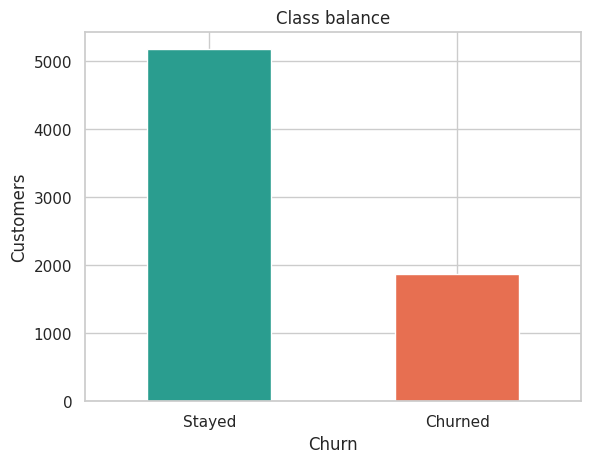

In [6]:
rate = df["Churn"].mean()
print(f"Churn rate: {rate:.1%}  ({df['Churn'].sum()} of {len(df)} customers)")
df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(color=["#2a9d8f", "#e76f51"], rot=0)
plt.title("Class balance"); plt.ylabel("Customers"); plt.show()

About 1 in 4 customers churn. That imbalance is why SMOTE and ROC-AUC (instead of plain accuracy) are used later.

### Contract, internet service and payment method

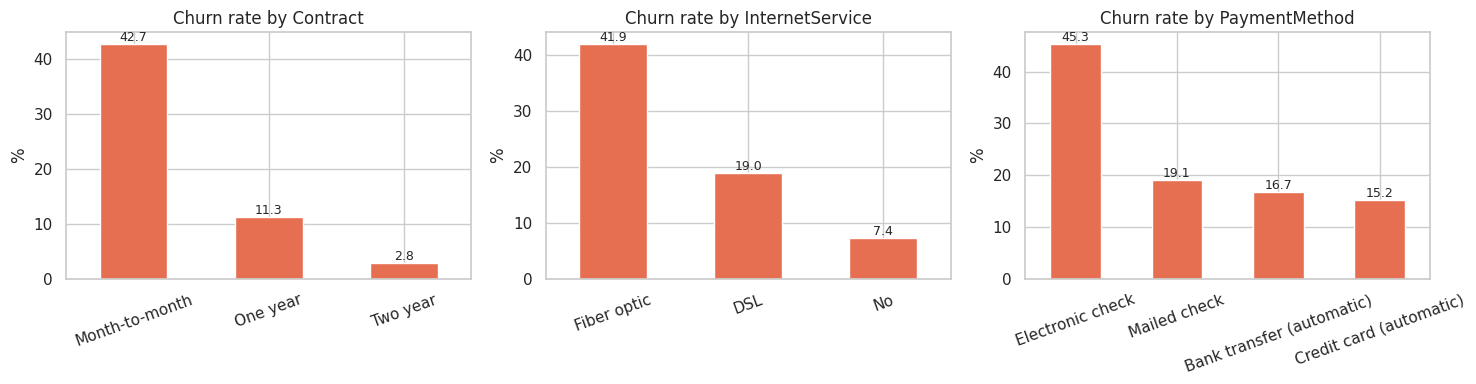

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df.groupby(col)["Churn"].mean().mul(100).sort_values(ascending=False)
    r.plot.bar(ax=ax, color="#e76f51", rot=20)
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("%"); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

Month-to-month contracts, fiber-optic internet and electronic-check payment are the high-churn groups.
Contract type separates customers the most: roughly 43% churn on month-to-month versus about 3% on two-year terms.

### Tenure and monthly charges

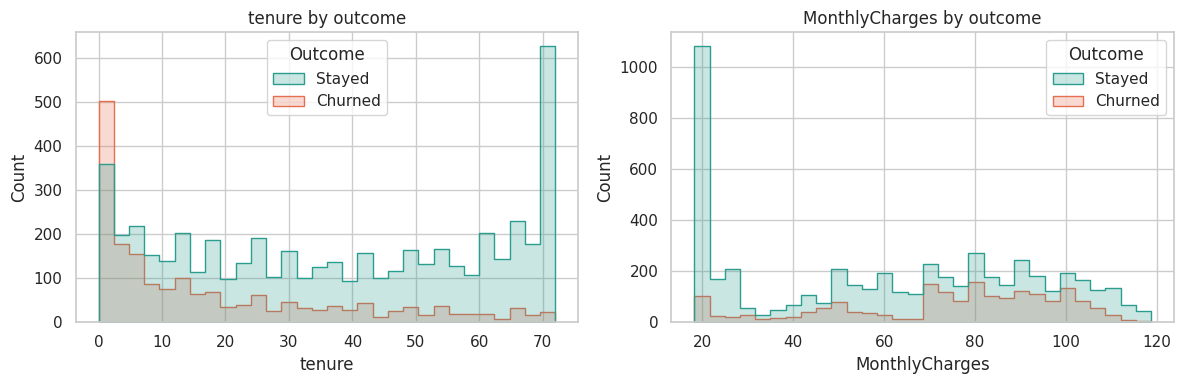

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges"]):
    sns.histplot(data=df.assign(Outcome=df.Churn.map({0: "Stayed", 1: "Churned"})),
                 x=col, hue="Outcome", bins=30, element="step", ax=ax,
                 palette={"Stayed": "#2a9d8f", "Churned": "#e76f51"})
    ax.set_title(f"{col} by outcome")
plt.tight_layout(); plt.show()

Churners are concentrated in the first months of tenure, and tend to have higher monthly bills.

### Add-on services

In [9]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
internet_users = df[df.InternetService != "No"]
tbl = pd.DataFrame({a: internet_users.groupby(a)["Churn"].mean().mul(100) for a in addons}).T.round(1)
tbl.columns.name = None
tbl

,No,Yes
OnlineSecurity,41.8,14.6
OnlineBackup,39.9,21.5
DeviceProtection,39.1,22.5
TechSupport,41.6,15.2
StreamingTV,33.5,30.1
StreamingMovies,33.7,29.9


Among internet customers, those *with* online security or tech support churn far less than those without.

### Correlation of numeric features

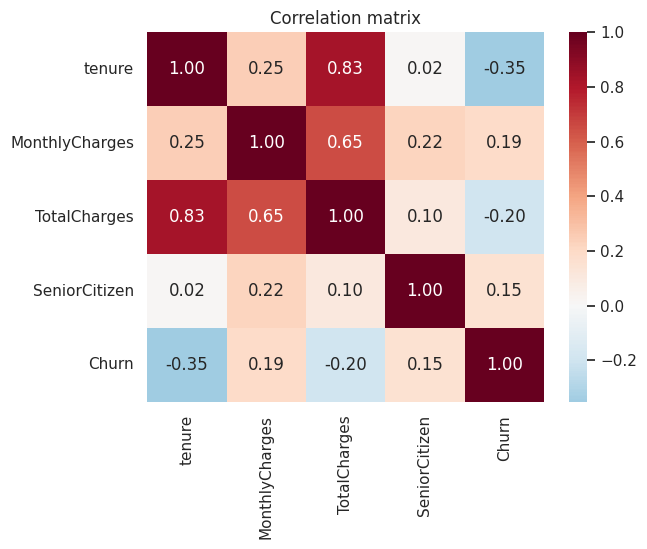

In [10]:
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]].corr(),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix"); plt.show()

`TotalCharges` is largely `tenure x MonthlyCharges`, so the two are strongly correlated. Tree models handle that fine, and regularised linear models cope with it too.

## 3. Train / test split

A stratified 80/20 split keeps the churn rate the same in both parts. The test set stays untouched until the end.

In [11]:
X, y = split_xy(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print("train churn rate:", round(y_train.mean(), 3), "| test churn rate:", round(y_test.mean(), 3))

(5634, 19) (1409, 19)
train churn rate: 0.265 | test churn rate: 0.265


## 4. Model comparison

Each model sits in the same pipeline: **scale + one-hot encode -> SMOTE -> classifier**.
Because SMOTE is *inside* the pipeline, cross-validation only oversamples the training folds. Oversampling before
splitting would leak synthetic copies of training rows into validation and inflate the scores.

In [12]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
rows = []
for name, est in candidates.items():
    pipe = make_pipeline(X_train, est)
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_train, y_train)
    test_auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    rows.append({"Model": name, "CV ROC-AUC": cv_auc.mean(), "CV std": cv_auc.std(), "Test ROC-AUC": test_auc})
comparison = pd.DataFrame(rows).set_index("Model").round(4)
comparison

,CV ROC-AUC,CV std,Test ROC-AUC
Model,,,
Logistic Regression,0.8447,0.0132,0.8399
Decision Tree,0.8172,0.0095,0.8131
Random Forest,0.8195,0.0109,0.8176
XGBoost,0.8226,0.0063,0.8207


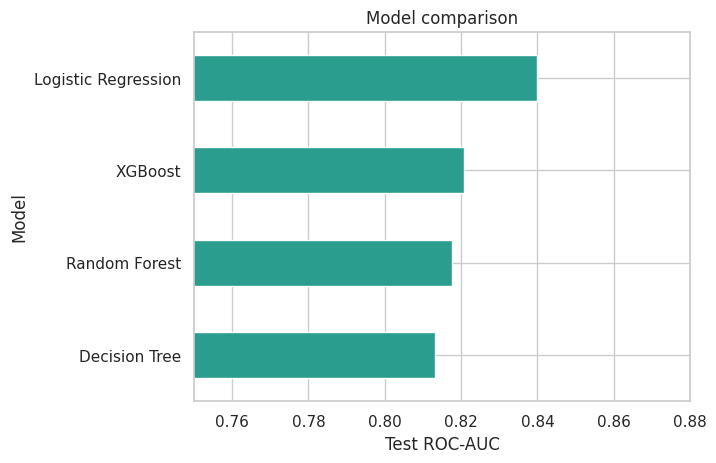

In [13]:
comparison["Test ROC-AUC"].sort_values().plot.barh(color="#2a9d8f")
plt.xlim(0.75, 0.88); plt.xlabel("Test ROC-AUC"); plt.title("Model comparison"); plt.show()

**Observation:** plain Logistic Regression is the strongest or tied for strongest, and the default tree ensembles trail it.
That suggests much of the signal in this dataset can be captured by a simple model, and the untuned tree ensembles may be fitting noise
(one thing worth testing, not something proven here). Tuning should close most of the gap.

## 5. Hyperparameter tuning (Random Forest)

`RandomizedSearchCV` samples 20 settings from the grid below, scoring each by 5-fold CV ROC-AUC.
Limiting tree depth and requiring more samples per leaf are the main levers against overfitting.

In [14]:
search = RandomizedSearchCV(
    make_pipeline(X_train, RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
    param_distributions={
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [8, 12, 16, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"],
    },
    n_iter=20, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
search.best_params_

Best CV ROC-AUC: 0.8437


{'model__n_estimators': 200,
 'model__min_samples_split': 2,
 'model__min_samples_leaf': 4,
 'model__max_features': 'sqrt',
 'model__max_depth': 8}

## 6. Evaluation on the held-out test set

In [15]:
best = search.best_estimator_
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print("Test ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))

Test ROC-AUC: 0.8377
              precision    recall  f1-score   support

      Stayed       0.89      0.77      0.83      1035
     Churned       0.54      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.76      0.77      1409



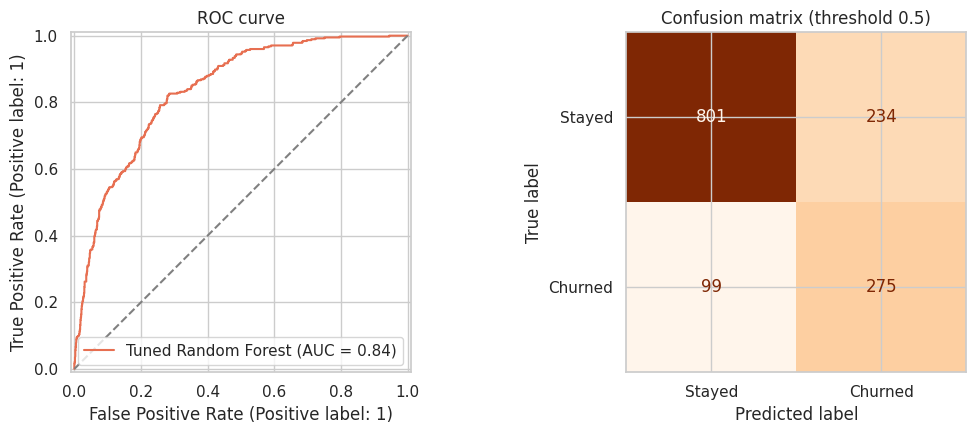

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[0], color="#e76f51", name="Tuned Random Forest")
axes[0].plot([0, 1], [0, 1], "--", color="grey"); axes[0].set_title("ROC curve")
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[1], cmap="Oranges",
                                        display_labels=["Stayed", "Churned"], colorbar=False)
axes[1].set_title("Confusion matrix (threshold 0.5)")
plt.tight_layout(); plt.show()

### Choosing a threshold

0.5 is just a default. The right cut-off depends on how costly a missed churner is compared with a wasted retention offer.

In [17]:
from sklearn.metrics import precision_score, recall_score
thr = pd.DataFrame([
    {"threshold": t,
     "precision": precision_score(y_test, proba >= t),
     "recall": recall_score(y_test, proba >= t),
     "flagged customers": int((proba >= t).sum())}
    for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("threshold").round(3)
thr

,precision,recall,flagged customers
threshold,,,
0.3,0.443,0.877,740
0.4,0.504,0.826,613
0.5,0.540,0.735,509
0.6,0.575,0.607,395
0.7,0.676,0.508,281


Lower thresholds catch more churners (higher recall) at the cost of contacting more customers who would have stayed.

## 7. Feature importance

Permutation importance shuffles one *original* column at a time and measures how much test ROC-AUC drops.
Working on raw columns keeps the answer in business terms (`Contract`, not `Contract_Two year`).

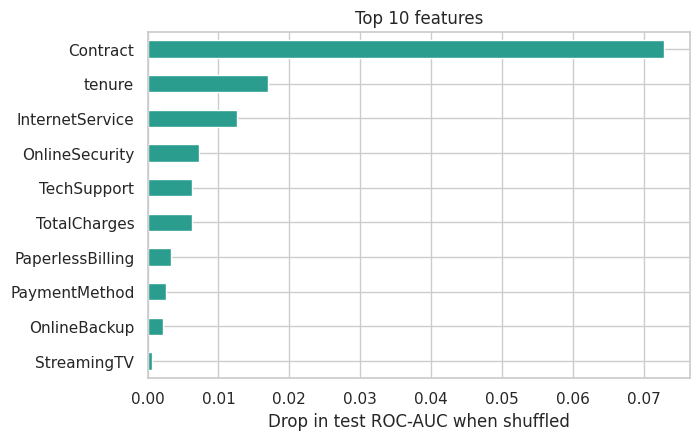

In [18]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_s.tail(10).plot.barh(color="#2a9d8f", figsize=(7, 4.5))
plt.xlabel("Drop in test ROC-AUC when shuffled"); plt.title("Top 10 features"); plt.show()

`Contract` dominates, followed by `tenure` and `InternetService`. Gender and phone service contribute almost nothing.

## 8. Scoring a single customer

This is the same call the Streamlit app makes.

In [19]:
def churn_probability(customer: dict) -> float:
    return float(best.predict_proba(pd.DataFrame([customer])[X.columns])[0, 1])

new_customer = dict(
    gender="Female", SeniorCitizen=0, Partner="No", Dependents="No", tenure=3,
    PhoneService="Yes", MultipleLines="No", InternetService="Fiber optic",
    OnlineSecurity="No", OnlineBackup="No", DeviceProtection="No", TechSupport="No",
    StreamingTV="No", StreamingMovies="No", Contract="Month-to-month",
    PaperlessBilling="Yes", PaymentMethod="Electronic check",
    MonthlyCharges=80.0, TotalCharges=240.0)

for contract in ["Month-to-month", "One year", "Two year"]:
    print(f"{contract:15s} -> {churn_probability({**new_customer, 'Contract': contract}):.1%}")

Month-to-month  -> 87.0%
One year        -> 42.1%
Two year        -> 38.2%


## Summary

- **Data:** 7,043 customers, 26.5% churn; 11 blank `TotalCharges` values (tenure 0) filled with 0.
- **Method:** preprocessing + SMOTE + classifier in one pipeline, so cross-validation is leak-free.
- **Models:** Logistic Regression was a very strong baseline; the tuned Random Forest closes the gap on the test set.
- **Drivers:** contract type, tenure, internet service, and the presence of security / support add-ons.
- **Next steps:** pick the threshold from a cost/benefit estimate, calibrate probabilities, add SHAP explanations.